In [1]:
from pathlib import Path

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import torch
import trimesh

from hac.constants import OBSERVERS
from hac.data import get_model_folder, load_data
from hac.eval import calculate_voxel_measure
from hac.lc2mesh.data import create_ellipsoidal_prior_mesh
from hac.lc2mesh.forward_model import AsteroidForwardModel, observers_to_unit_tensor
from hac.lc2mesh.metrics import compute_per_camera_metrics
from hac.lc2mesh.utils import set_seed, setup_device
from hac.lc2mesh.visualization import (
    plot_camera_grid,
    plot_interactive_mesh,
    plot_lightcurve_comparison,
)
from hac.mesh import normalize_mesh_to_challenge_cylinder

def facet_geometry(vertices: torch.Tensor, faces: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """Facet normals [F,3] and areas [F] from vertices [V,3] (differentiable)."""
    tri = vertices[faces]  # [F, 3, 3]
    edge1 = tri[:, 1] - tri[:, 0]
    edge2 = tri[:, 2] - tri[:, 0]
    cross = torch.cross(edge1, edge2, dim=1)
    twice_area = cross.norm(dim=1)
    normals = cross / twice_area.clamp_min(1e-12).unsqueeze(1)
    return normals, 0.5 * twice_area

def predicted_lightcurves_from_mesh(vertices: torch.Tensor, faces: torch.Tensor) -> torch.Tensor:
    normals, areas = facet_geometry(vertices, faces)
    fm = AsteroidForwardModel(
        normals=normals,
        lambert_weight=LAMBERT_WEIGHT,
    )
    A = fm.build_forward_matrix(phases=phases, e_sun=e_sun, e_obs=e_obs)
    raw = torch.einsum("cpf,f->cp", A, areas)
    return raw / raw.mean(dim=1, keepdim=True).clamp_min(1e-12)

torch.set_default_dtype(torch.float64)

In [2]:
# --- Quick selector: choose asteroid + reconstruction variant ---
SELECTED_ASTEROID_ID = 3
PRIOR_SHAPE_TYPE = "ellipsoid"  # "ellipsoid", "peanut", "cube", "diamond" or "irregular"

if SELECTED_ASTEROID_ID not in list(range(1, 11)):
    raise ValueError(
        f"SELECTED_ASTEROID_ID must be in 1-10, got {SELECTED_ASTEROID_ID}"
    )
if PRIOR_SHAPE_TYPE not in {"ellipsoid", "peanut", "cube", "diamond", "irregular"}:
    raise ValueError(
        f"PRIOR_SHAPE_TYPE must be one of 'ellipsoid', 'peanut', 'cube', 'diamond', or 'irregular', got {PRIOR_SHAPE_TYPE!r}"
    )

print(f"Selected asteroid: {SELECTED_ASTEROID_ID}")
print(f"Prior shape type: {PRIOR_SHAPE_TYPE}")

Selected asteroid: 3
Prior shape type: ellipsoid


In [3]:
# --- Config + data loading ---
ASTEROID_ID = SELECTED_ASTEROID_ID
CURVE_TYPE = "intensity"
SEED = 42
TARGET_GPU_ID = 0
N_SUBDIVISIONS = 4
LAMBERT_WEIGHT = 0.3
TARGET_CAM = "135_hor1"

set_seed(SEED)
device = setup_device(TARGET_GPU_ID)

recon_dir = Path("recon")
recon_stl_file = recon_dir / f"prior_{PRIOR_SHAPE_TYPE}_asteroid{ASTEROID_ID}.stl"

camera_names, e_obs = observers_to_unit_tensor(OBSERVERS, device=device, dtype=torch.float64)
e_sun = torch.tensor([-1.0, 0.0, 0.0], dtype=torch.float64, device=device)

ds_real = load_data(ASTEROID_ID, origin="real", curve_type=CURVE_TYPE)
observed = torch.as_tensor(
    ds_real.data[camera_names].to_numpy(dtype=np.float64, copy=True).T,
    dtype=torch.float64,
    device=device,
)
observed_norm = observed / observed.mean(dim=1, keepdim=True).clamp_min(1e-12)
n_phase = observed.shape[1]
phases = torch.arange(n_phase, dtype=torch.float64, device=device) * (2.0 * torch.pi / n_phase)

prior = create_ellipsoidal_prior_mesh(
    asteroid_id=ASTEROID_ID, subdivisions=N_SUBDIVISIONS, device=device, shape_type=PRIOR_SHAPE_TYPE
)
R_CYL = float(prior["R_CYLINDER"])

if not recon_stl_file.exists():
    raise FileNotFoundError(f"Reconstruction STL not found: {recon_stl_file.resolve()}")

recon_mesh_raw = trimesh.load_mesh(recon_stl_file)
recon_mesh = normalize_mesh_to_challenge_cylinder(recon_mesh_raw, R_CYL)
recon_vertices = torch.as_tensor(recon_mesh.vertices, dtype=torch.float64, device=device)
recon_faces = torch.as_tensor(recon_mesh.faces, dtype=torch.long, device=device)

model_dir = get_model_folder(ASTEROID_ID)
gt_stl_file = model_dir / f"asteroid{ASTEROID_ID}.stl"
GT_EXIST = gt_stl_file.exists()
true_mesh = None
if GT_EXIST:
    true_mesh = normalize_mesh_to_challenge_cylinder(trimesh.load_mesh(gt_stl_file), R_CYL)
else:
    print(f"Warning: GT STL file not found at {gt_stl_file}")

print(f"Asteroid {ASTEROID_ID}: cameras={len(camera_names)}, phases={n_phase}")
print(f"Reconstruction STL: {recon_stl_file.resolve()}")
print(f"Cylinder radius: {R_CYL:.3f}")

pred_norm = predicted_lightcurves_from_mesh(recon_vertices, recon_faces)
per_camera_df = compute_per_camera_metrics(observed_norm, pred_norm, camera_names)

Device: cuda:0 (Tesla V100-SXM2-32GB)
Visible CUDA devices: 8
Asteroid 3: cameras=28, phases=842
Reconstruction STL: /home/opis/iayad/WORK/HAC-DTU/workspaces/ishak/recon/prior_ellipsoid_asteroid3.stl
Cylinder radius: 0.880


In [4]:
# --- Reconstruction mesh visualization + GT comparison ---
fig_mesh = plot_interactive_mesh(
    vertices=recon_mesh.vertices,
    faces=recon_mesh.faces,
    title=(
        f"Asteroid {ASTEROID_ID}: reconstructed mesh ({recon_mesh.faces.shape[0]} faces) | "
        f"mean_r={per_camera_df['Pearson_R'].mean():.3f}"
    ),
    mesh_color="#c0b08a",
    show_edges=False,
)
fig_mesh.show()

if GT_EXIST and true_mesh is not None:
    gt_fig_mesh = plot_interactive_mesh(
        vertices=true_mesh.vertices,
        faces=true_mesh.faces,
        title=f"Asteroid {ASTEROID_ID}: GT mesh, cylinder-normalized ({true_mesh.faces.shape[0]} faces)",
        mesh_color="#a0c0ff",
        show_edges=False,
    )
    gt_fig_mesh.show()

print(
    f"Reconstruction extents: "
    f"x[{recon_mesh.vertices[:, 0].min():.3f}, {recon_mesh.vertices[:, 0].max():.3f}] "
    f"y[{recon_mesh.vertices[:, 1].min():.3f}, {recon_mesh.vertices[:, 1].max():.3f}] "
    f"z[{recon_mesh.vertices[:, 2].min():.3f}, {recon_mesh.vertices[:, 2].max():.3f}] "
    f"(cylinder bound: R={R_CYL}, z in [-1, 1])"
)

if GT_EXIST and true_mesh is not None:
    print(
        f"GT extents: "
        f"x[{true_mesh.vertices[:, 0].min():.3f}, {true_mesh.vertices[:, 0].max():.3f}] "
        f"y[{true_mesh.vertices[:, 1].min():.3f}, {true_mesh.vertices[:, 1].max():.3f}] "
        f"z[{true_mesh.vertices[:, 2].min():.3f}, {true_mesh.vertices[:, 2].max():.3f}]"
    )
    pred_mesh = trimesh.Trimesh(vertices=recon_mesh.vertices, faces=recon_mesh.faces, process=False)
    score = calculate_voxel_measure(true_mesh, pred_mesh)
    print(f"Voxel measure between predicted mesh and GT mesh: {score:.6f}")
else:
    print("GT mesh not available -> skipping voxel measure calculation.")

Reconstruction extents: x[-0.879, 0.879] y[-0.750, 0.750] z[-1.000, 1.000] (cylinder bound: R=0.88, z in [-1, 1])
GT extents: x[-0.846, 0.846] y[-0.617, 0.617] z[-1.000, 1.000]
Voxel measure between predicted mesh and GT mesh: 0.094723


Final lightcurve fit: mean_r=0.9157, min_r=0.7359, mean MSE=0.004508


,MSE,MAE,Pearson_R
Camera,,,
135_hor2,0.020406,0.115185,0.735906
135_hor1,0.019590,0.117290,0.755185
225_hor2,0.017007,0.104490,0.809894
270_bottom,0.003729,0.050952,0.812896
270_top,0.009741,0.071142,0.817973
225_hor1,0.012458,0.091448,0.846096
225_bottom,0.005234,0.062420,0.890366
270_hor1,0.003248,0.046635,0.902343
45_hor1,0.001435,0.032158,0.904429


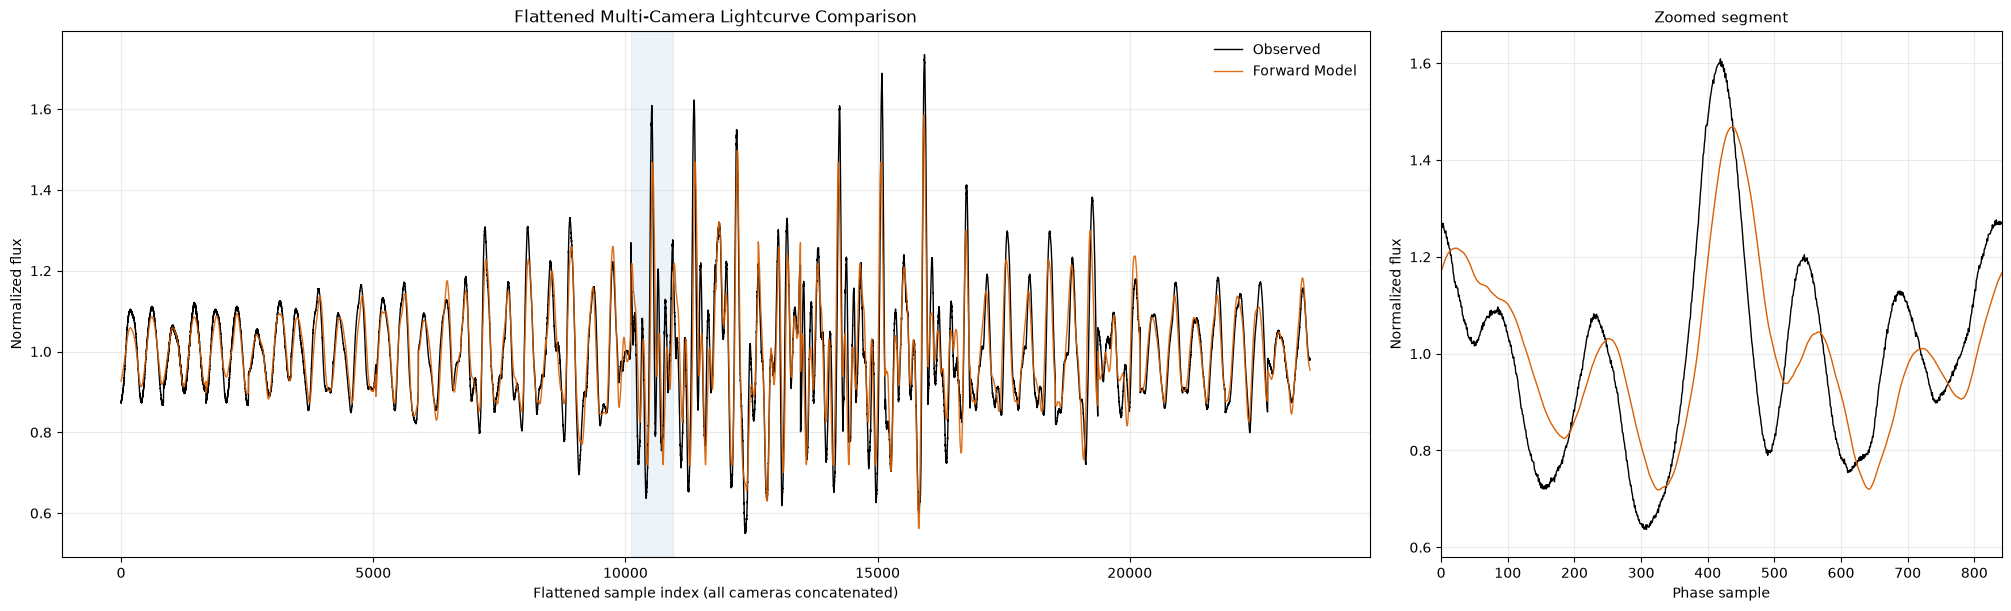

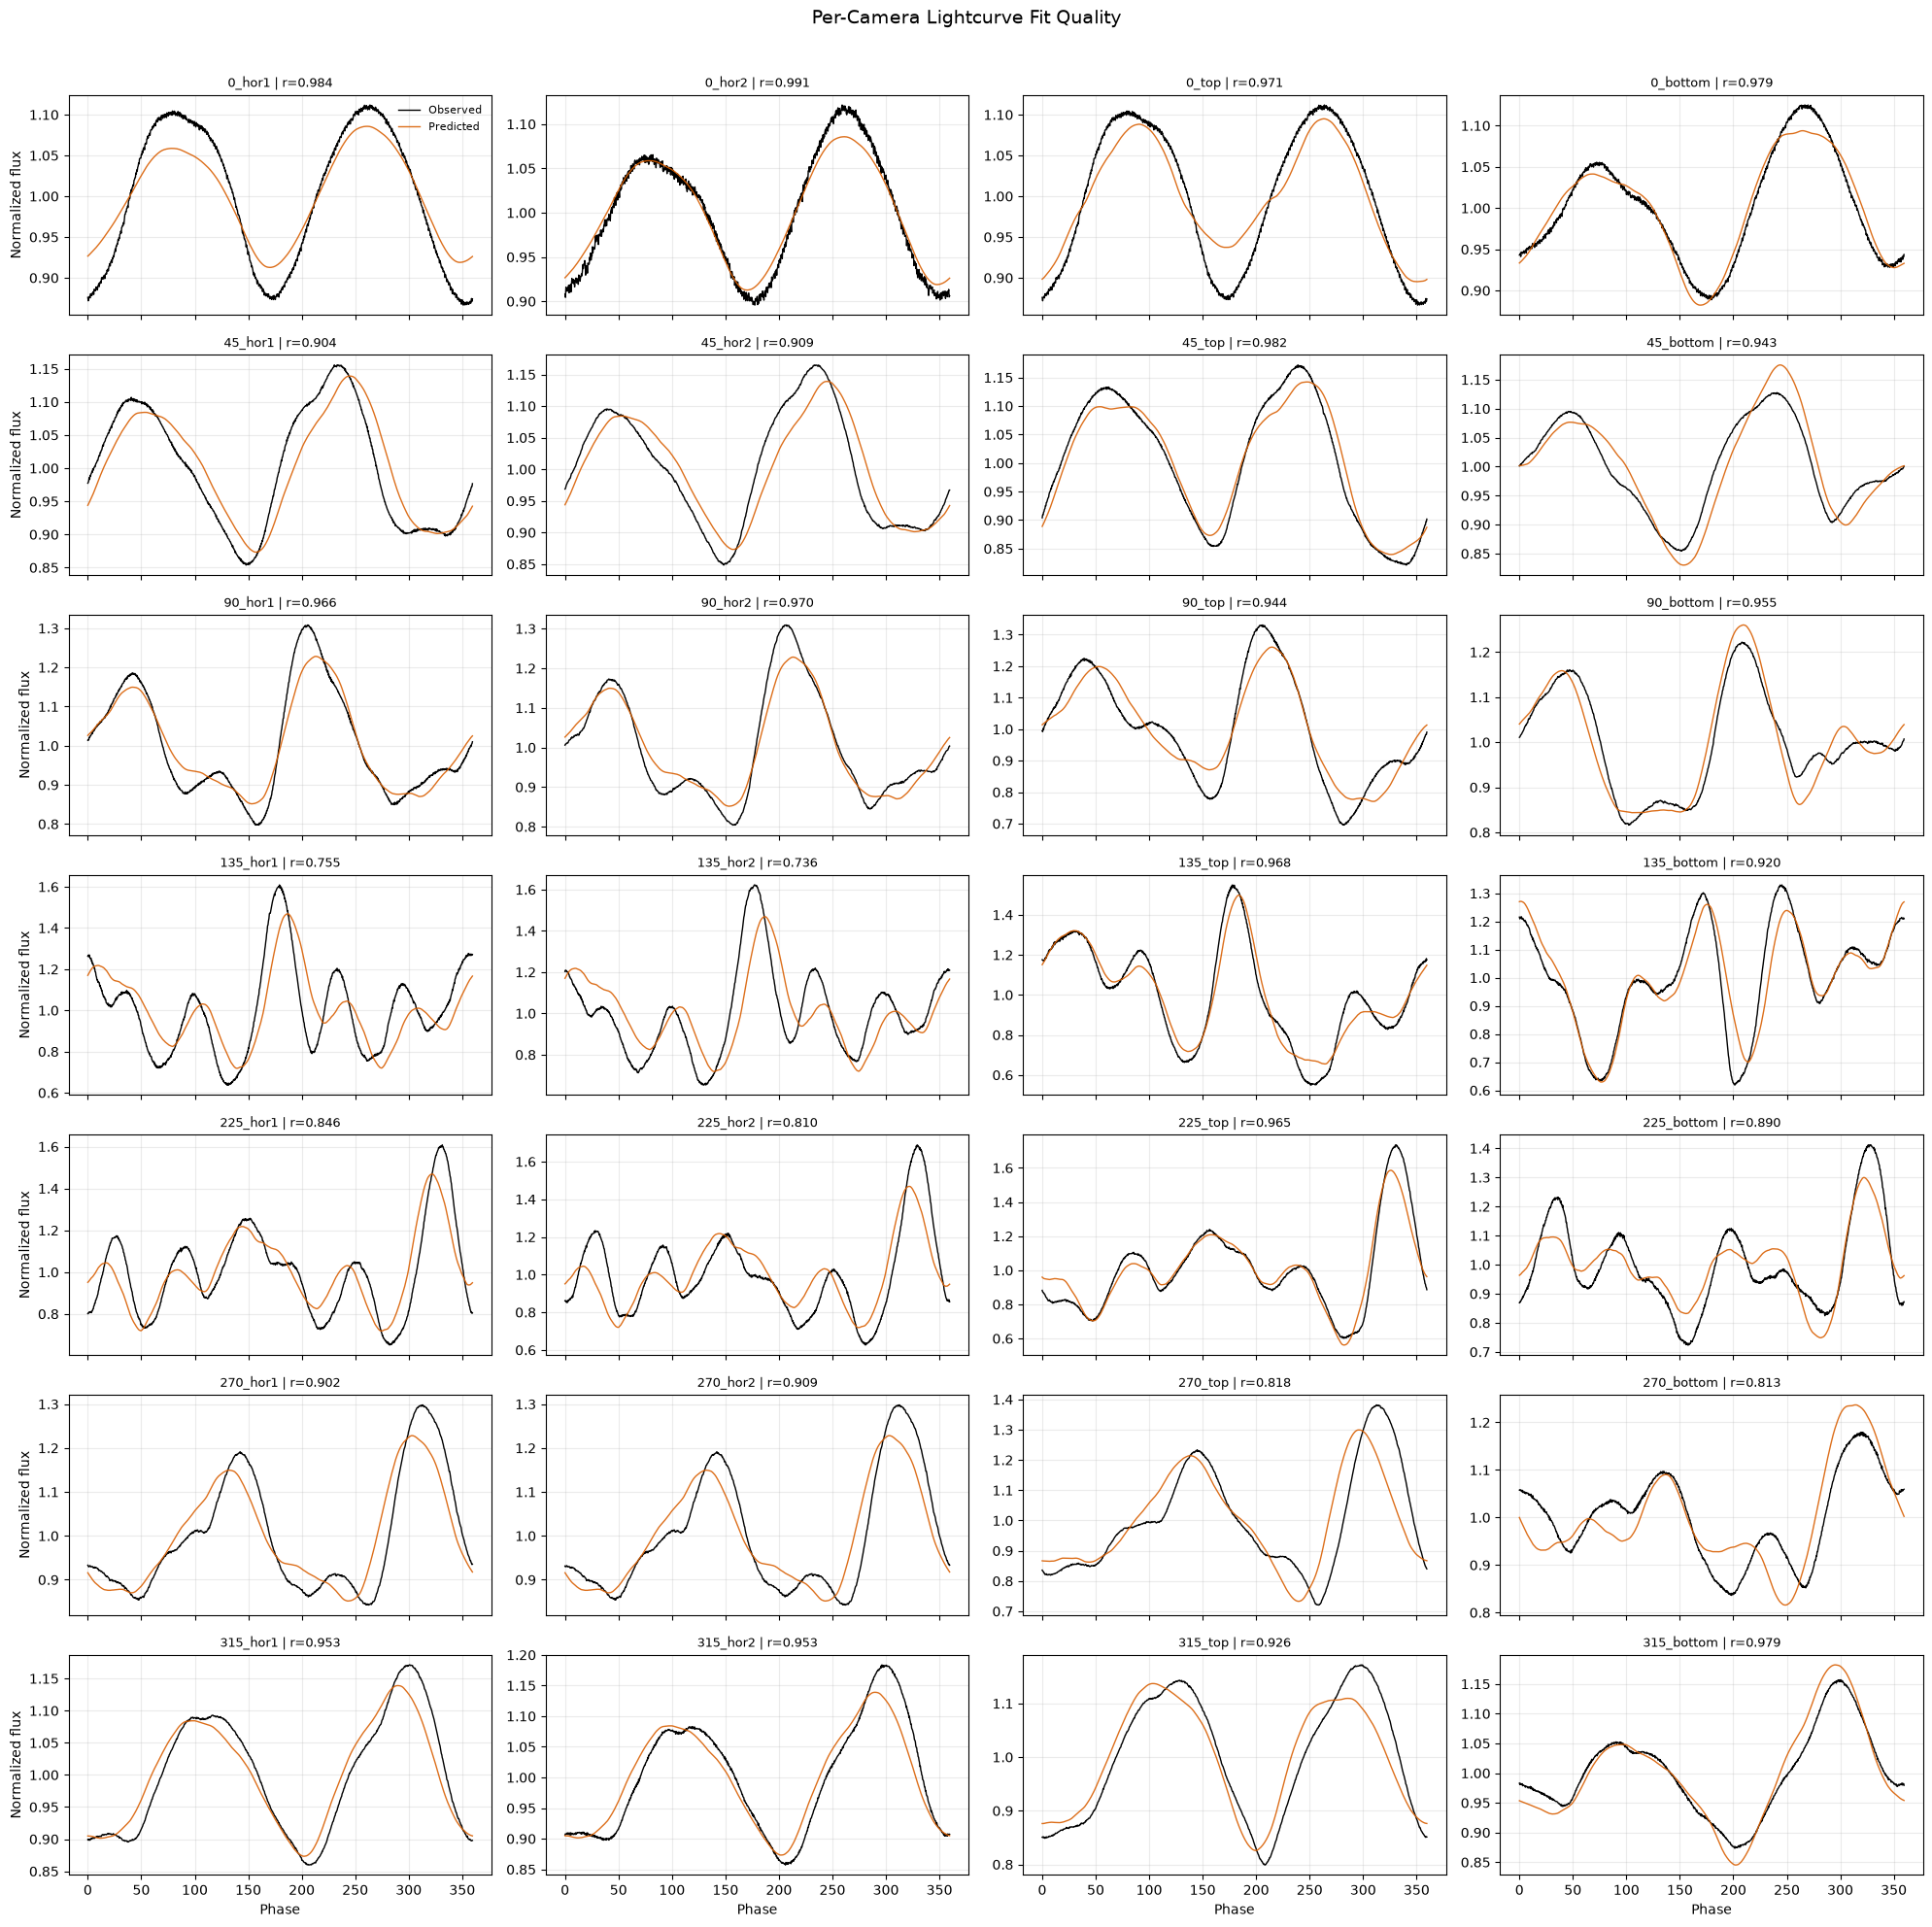

In [5]:
# --- Lightcurve comparison plots ---

print(
    f"Final lightcurve fit: mean_r={per_camera_df['Pearson_R'].mean():.4f}, "
    f"min_r={per_camera_df['Pearson_R'].min():.4f}, "
    f"mean MSE={per_camera_df['MSE'].mean():.6f}"
)
display(per_camera_df.sort_values("Pearson_R"))

target_cam = TARGET_CAM if TARGET_CAM in camera_names else camera_names[0]
fig, _ = plot_lightcurve_comparison(
    obs_norm=observed_norm.detach().cpu().numpy(),
    pred_norm=pred_norm.detach().cpu().numpy(),
    camera_keys=camera_names,
    target_cam_id=target_cam,
)
plt.show()

phase_deg = np.rad2deg(phases.detach().cpu().numpy())
fig, _ = plot_camera_grid(observed_norm, pred_norm, camera_names, phase_axis=phase_deg)
plt.show()